# 04 - Process discovery

Draws the real patient pathways as process models. The figures are produced by `src/discovery.py` and saved in `reports/figures/`; this notebook shows them and explains how to read them.

Two logs are used:
- **All activities:** every event, including the repeated lab tests.
- **Clinical steps (milestone):** lab tests removed, as in the variant analysis.

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent
FIGURES = ROOT / 'reports' / 'figures'
sys.path.append(str(ROOT / 'src'))

import discovery  # re-run `python src/discovery.py` to regenerate the figures

## 1. Directly-follows graph with lab tests
Each box is an activity (number = how often it occurs), each arrow means "this step directly followed that step" (number = how often). Only the most frequent paths are drawn.

The lab tests dominate: Leucocytes and CRP follow each other thousands of times, which hides the clinical pathway.

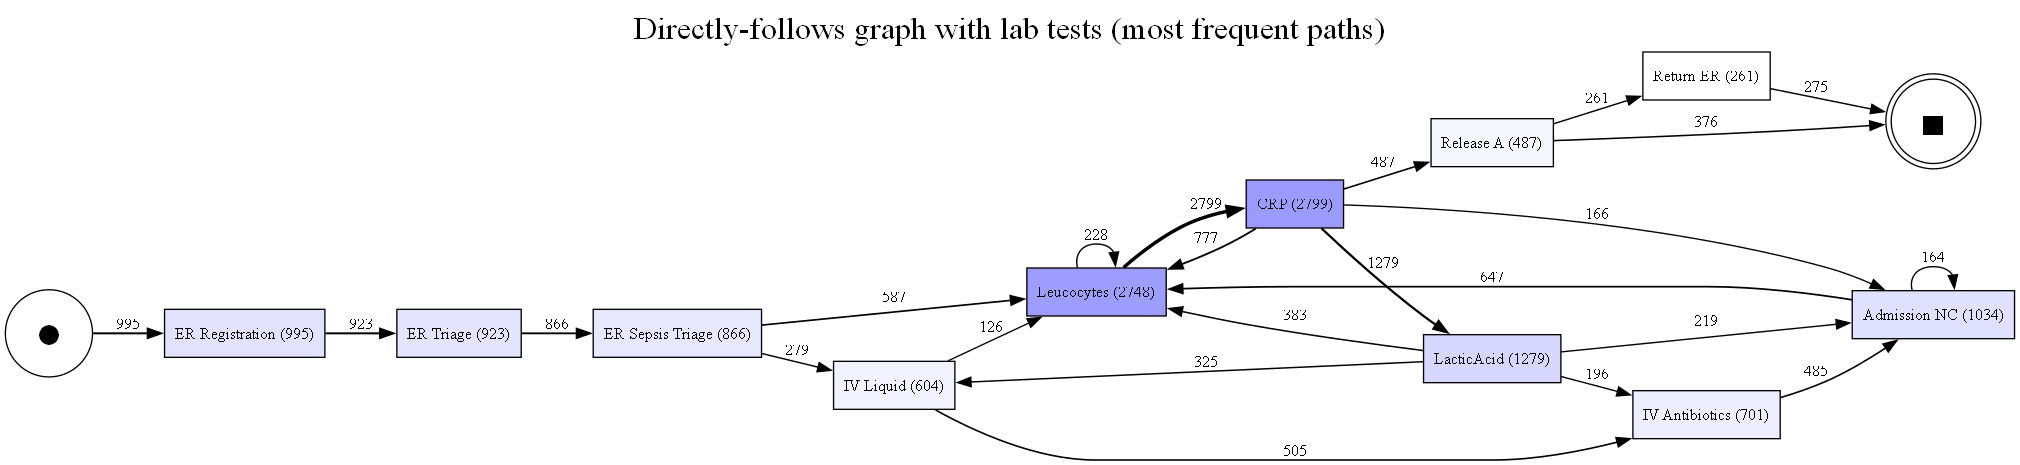

In [2]:
display(Image(FIGURES / 'process_dfg_all_activities.png', width=1000))

## 2. Directly-follows graph, clinical steps
Without the lab tests the clinical pathway is easy to read. Darker boxes and thicker arrows mean more patients.

Note: only the most frequent paths are drawn, so the numbers can be slightly lower than the full totals.

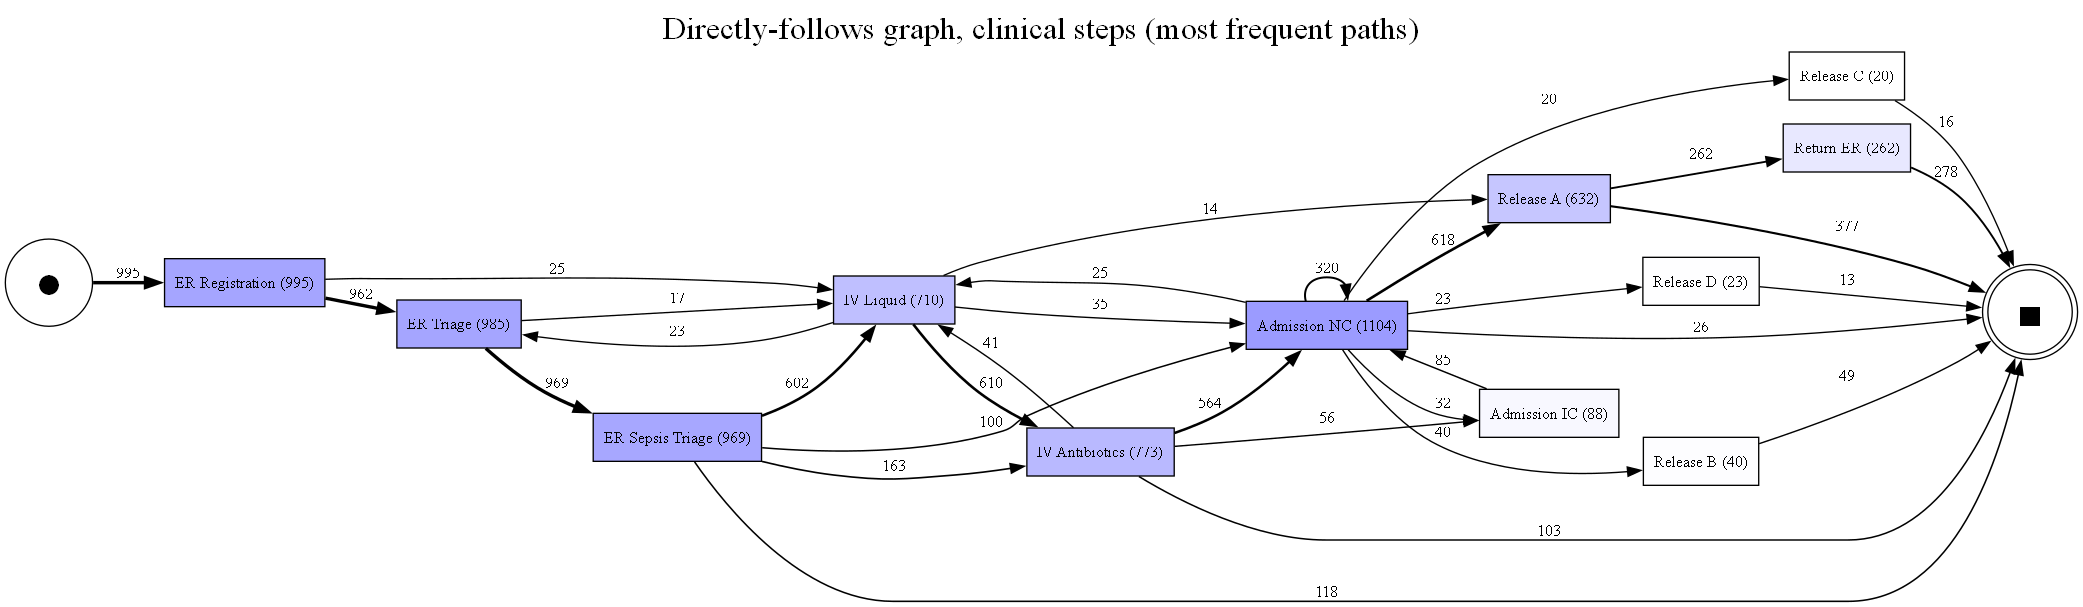

In [3]:
display(Image(FIGURES / 'process_dfg_milestone.png', width=1000))

## 3. Heuristics net
Keeps only strong, frequent relations (dependency at least 0.8, seen at least 20 times). The numbers here are the exact totals.

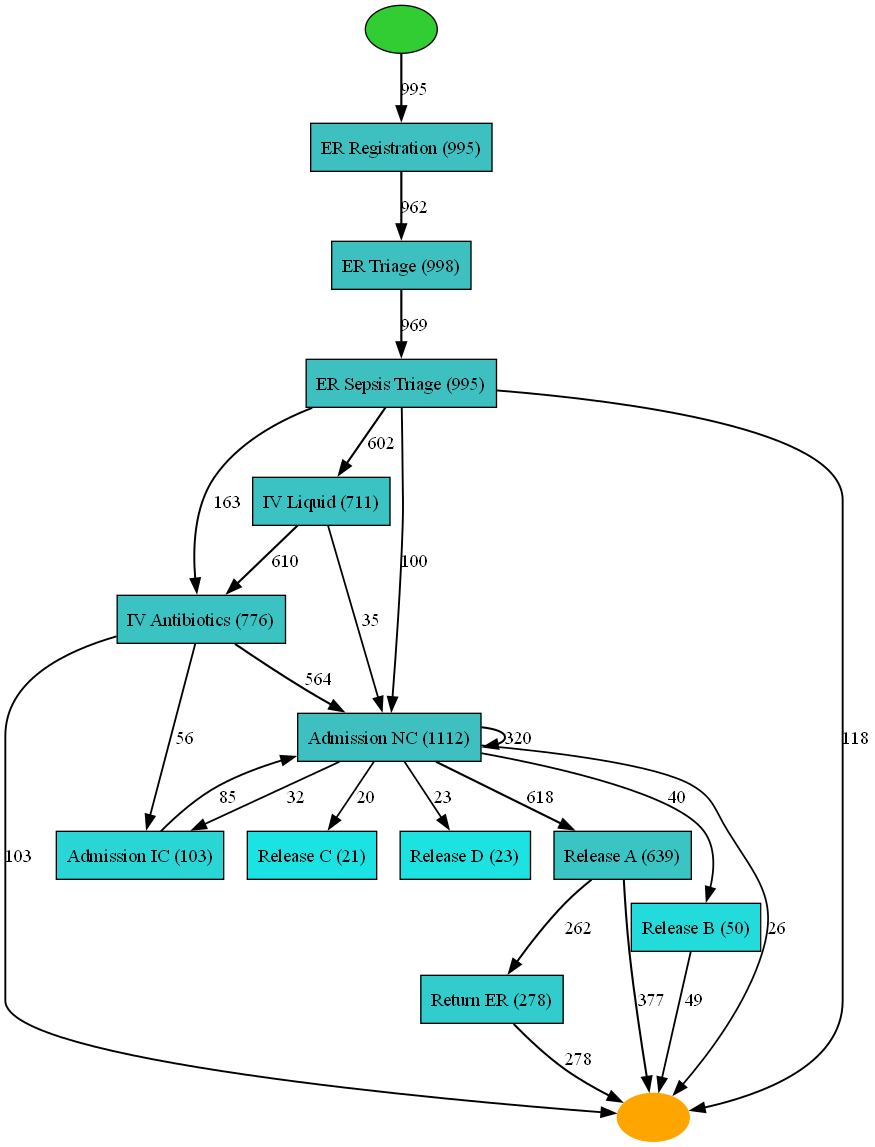

In [4]:
display(Image(FIGURES / 'process_heuristics_milestone.png', width=520))

## 4. Petri net (inductive miner)
A formal model. Boxes are activities, circles are states, and **black boxes are silent steps** (routing choices that are not real activities). It ignores the 20% rarest behaviour.

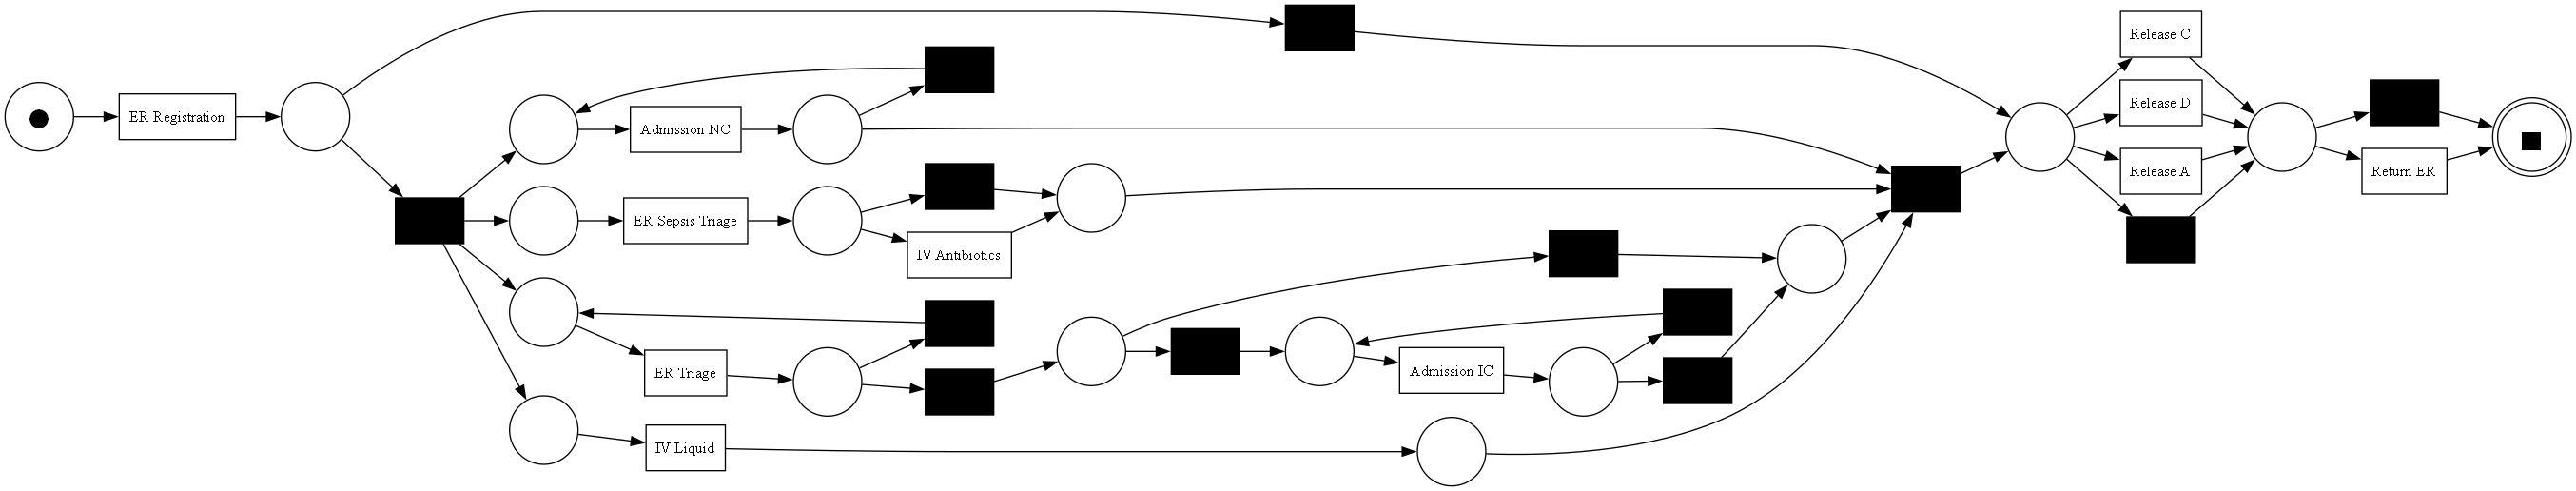

In [5]:
display(Image(FIGURES / 'process_petri_inductive.png', width=1000))

## 5. How good are the models?
- **Fitness:** how well the model replays the real cases (1 = all behaviour is allowed by the model).
- **Perfectly fitting cases:** share of cases the model replays without any problem.
- **Precision:** how little extra behaviour the model allows (1 = it allows only what happened).
- **F-score:** the balance of fitness and precision.

In [6]:
pd.read_csv(ROOT / 'reports' / 'model_evaluation.csv')

,model,log,fitness,perfectly_fitting_cases_pct,precision,f_score,places,transitions,arcs
0,"Inductive miner, no noise filter",milestone,1.000,100.0,0.512,0.677,22,29,66
1,"Inductive miner, noise 20%",milestone,0.916,60.6,0.649,0.760,18,24,54
2,"Heuristics miner, dependency 0.8",milestone,0.931,15.0,0.937,0.934,23,36,83
3,"Inductive miner, noise 20%",all activities,0.931,67.9,0.405,0.564,22,26,64


## Findings
- **The main route** is Registration, Triage, Sepsis triage, IV fluid, IV antibiotics, ward admission, then Release A. 602 patients go from sepsis triage to IV fluid, 610 from IV fluid to antibiotics, 564 from antibiotics to the ward, and 618 from the ward to Release A.
- **Not everyone follows it.** 163 patients get antibiotics without IV fluid, and 100 go from sepsis triage straight to the ward.
- **Many pathways end early.** 118 patients end right after sepsis triage and about 100 after antibiotics, with no admission or release recorded. This is consistent with the 256 cases without a `Release` event.
- **Returns come after Release A.** 262 of the 278 returns to the ER follow Release A. Releases B, C and D end the case directly, with no return.
- **Intensive care is a side route.** Patients enter it mostly from antibiotics (56) or the ward (32), and 85 move back to the ward afterwards.
- **Ward admission is recorded more than once.** `Admission NC` occurs about 1,100 times for 756 patients, with 320 repeats directly after each other. This could be transfers or repeated records and should be checked with the mentor.
- **Lab tests add complexity, not pathway variety.** Including them lowers precision of the same miner from 0.65 to 0.41.
- **Model trade-off:** the inductive miner without noise filtering replays every case (fitness 1.0) but allows a lot of behaviour that never happened (precision 0.51). With the 20% noise filter it is simpler but only 61% of cases replay perfectly. The heuristics model is the most precise (0.94) but only 15% of cases replay perfectly, likely because it does not allow all the repeated steps seen in the data. Conformance checking (next phase) will look at this more closely.
- **Which to show:** use the DFG and heuristics map to explain the pathway, and the Petri net as the formal model.
- **Next step:** add waiting times to these maps to find the bottlenecks (commit 9).